# Delft3D-FM particle tracking with dorado

This Python notebook uses the $\href{https://github.com/passaH2O/dorado}{\textbf{dorado}}$ library by $\href{https://joss.theoj.org/papers/10.21105/joss.02585#}{\textbf{Hariharan et al. (2020)}}$ to generate a particle tracking experiment for a Delft3D-FM unsteady simulation. This workflow combines the scripts $\href{https://github.com/passaH2O/dorado/blob/master/examples/unstructured_grid_anuga.ipynb}{\texttt{unstructured\_grid\_anuga.ipynb}}$ by Kyle Wright and Jay Hariharan (July, 2020) and $\href{https://github.com/passaH2O/dorado/blob/master/examples/unstructured_grid_Delft3dFM.ipynb}{\texttt{unstructured\_grid\_Delft3dFM.ipynb}}$ by Caitlin R. R. Turner (July, 2025).

$\textbf{NOTES}$:
- The script asks to define a time period (consistent with the simulation) and a portion of the domain to reduce computational time.
- The script uses the Lake Seminole Delft3D-FM model and focuses on the Chattahoochee arm of the lake. 
- The script opens a window and asks to select the simulation folder. Note that it assumes a $\texttt{dimr}$ configuration and it looks for a $\texttt{dflowfm}$ folder and a $\texttt{output}$ subfolder containing the netcdf file(s).
- The script requires the $\href{https://github.com/Deltares/dfm_tools}{\texttt{dfm\_tools}}$ package by Deltares to easily load simulation outputs. 
- The particles are injected one time at the top of the delta.

In [1]:
# --- General libraries ---
import os
import glob
import pandas as pd
import numpy as np
import datetime as dt
import json
import geopandas as gpd
from shapely.geometry import Point
from tqdm.auto import tqdm
import random
import time
import gc
from scipy.optimize import curve_fit
import pickle

# --- Libraries for interactive folder/file selection ---
import tkinter as tk
from tkinter import filedialog

# -- Tools to process Delft3D-FM output ---
import dfm_tools as dfmt
import xarray as xr

# --- Dorado particle tracking ---
import dorado
import dorado.routines as routines
from dorado.routines import draw_travel_path
import dorado.particle_track as pt

# --- Plotting ---
import matplotlib
matplotlib.rcParams['font.family']           = 'Arial'
matplotlib.rcParams['axes.titlesize']        = 13  # Figure title size
matplotlib.rcParams['axes.labelsize']        = 12  # Axis label size
matplotlib.rcParams['xtick.labelsize']       = 12  # X tick labels size
matplotlib.rcParams['ytick.labelsize']       = 12  # Y tick labels size
matplotlib.rcParams['legend.title_fontsize'] = 12  # Legend title size
matplotlib.rcParams['legend.fontsize']       = 11  # Legend label size

import matplotlib.pyplot as plt
import matplotlib.animation as animation
import matplotlib.colors as mcolors
from cmcrameri import cm
import matplotlib.image as mpimg
import matplotlib.patheffects as path_effects
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.colors import Normalize
from mpl_toolkits.axes_grid1 import make_axes_locatable
import imageio.v2 as imageio

In [2]:
# With or withtout hydropeaking?
hydrograph = 'Hydropeaking'  # Natural/Hydropeaking

# --- Time period to consider ---
tin  = '2020-07-01 00:00:00'
tend = '2020-09-01 00:00:00'

# --- Select domain ---
lon_min = 697000
lon_max = 705000
lat_min = 3397915
lat_max = 3411500

# ---- Don't modify this line! ------
# Convert start time string to datetime for particle tracking animation
start_time = dt.datetime.strptime(tin, '%Y-%m-%d %H:%M:%S')

## Load and store simulation results

Select the simulation folder. Once loaded the results are sliced within the time and space window. Then, longitude, latitude, bed level, time, water depth, water level, flow velocity x-component and flow velocity y-component are stored into a dictionary. Finally, the script finds and counts the number of NaN values for each variable. The following cell allows to save the dictionary on a text file (not necessary).

In [3]:
root = tk.Tk()
root.withdraw() # Hide the main Tkinter window
root.attributes('-topmost', True)

# Ask to select a folder
folder_path  = filedialog.askdirectory(title="Select simulation directory")

if folder_path:
    print("Selected folder:", folder_path, "\n")
          
    # Create a folder where we save figures and other post-processing stuff
    output_folder = os.path.join(folder_path, "particle_tracking_staggered_drops")
    os.makedirs(output_folder, exist_ok = True)
else:
    print("!!! No folder selected !!!")

# Read FlowFM_map.nc
map_netcdf = os.path.join(folder_path, "dflowfm", "output", 'FlowFM_*_map.nc')
print("Reading:", map_netcdf, "\n")
map_xr = dfmt.open_partitioned_dataset(map_netcdf)

# Slice data
# Time
print("Slicing time ...")
map_xr = map_xr.sel(time=slice(tin, tend))

# Just a check for the timestep in seconds -> we need this number later
time_diff = (map_xr.time.values[1] - map_xr.time.values[0]).astype('timedelta64[s]')
print(f"netCDF output timestep is: {time_diff}")

# Space
print("and space ...\n")
map_xr = map_xr.ugrid.sel(x=slice(lon_min, lon_max), y=slice(lat_min, lat_max))         

# Store the necessary variables into a dictonary
unstructured = dict()
unstructured['x']         = map_xr.mesh2d_face_x.values.astype(np.float32)      # longitude
unstructured['y']         = map_xr.mesh2d_face_y.values.astype(np.float32)      # latitude
unstructured['time']      = map_xr.time.values.astype(np.float32)               # time
unstructured['elevation'] = map_xr.mesh2d_flowelem_bl.values.astype(np.float32) # bed level 
unstructured['stage']     = map_xr.mesh2d_s1.values.astype(np.float32)          # water level
unstructured['depth']     = map_xr.mesh2d_waterdepth.values.astype(np.float32)  # water depth
unstructured['u']         = map_xr.mesh2d_ucx.values.astype(np.float32)         # velocity x-component
unstructured['v']         = map_xr.mesh2d_ucy.values.astype(np.float32)         # velocity y-component

# Freeing up memory from initial NetCDF load
del map_xr 
gc.collect() # Force Python to release unreferenced memory <- this helps for later 

# --- Run a check for NaNs ---
print("\nField summary (length, shape, NaNs)")
for key, arr in unstructured.items():
    arr_np = np.array(arr, dtype=np.float32)
    nan_count = np.isnan(arr_np).sum()
    total = arr_np.size
    pct = (nan_count / total * 100) if total > 0 else 0
    print(f"{key:12s} | shape: {arr_np.shape!s:20s} | length: {total:8d} | NaNs: {nan_count:8d} ({pct:6.2f}%)")

Selected folder: D:/LakeSeminole/OnlyHydro_HydropeakingPaper/Chatta_Hydropeaking_Year 

Reading: D:/LakeSeminole/OnlyHydro_HydropeakingPaper/Chatta_Hydropeaking_Year\dflowfm\output\FlowFM_*_map.nc 

>> xu.open_dataset() with 14 partition(s): 1 2 3 4 5 6 7 8 9 10 11 12 13 14 : 1050.72 sec
>> xu.merge_partitions() with 14 partition(s): 20.74 sec
>> dfmt.open_partitioned_dataset() total: 1071.46 sec
Slicing time ...
netCDF output timestep is: 3600 seconds
and space ...


Field summary (length, shape, NaNs)
x            | shape: (54996,)             | length:    54996 | NaNs:        0 (  0.00%)
y            | shape: (54996,)             | length:    54996 | NaNs:        0 (  0.00%)
time         | shape: (1489,)              | length:     1489 | NaNs:        0 (  0.00%)
elevation    | shape: (54996,)             | length:    54996 | NaNs:        0 (  0.00%)
stage        | shape: (1489, 54996)        | length: 81889044 | NaNs: 32125237 ( 39.23%)
depth        | shape: (1489, 54996)        | l

## Convert to structured grid
The script loads the latitude and longitude of model's boundary. The coordinates are stored in a separate $\texttt{model.csv}$ file. Then, the function $\texttt{unstruct2grid}$ is used to make the conversion that uses the IDW interpolation. Finally, the injection point is defined and a simple map is saved showing the structured bed level with the injection point.

---> Particles will be injected in [(32, 20)]


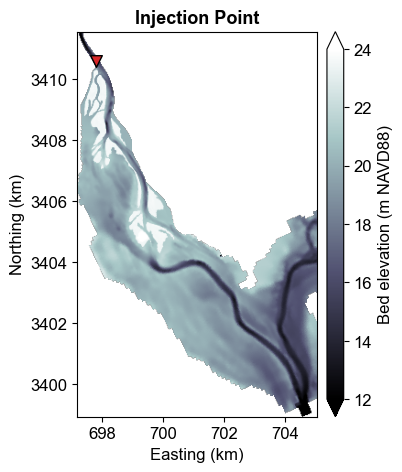

In [4]:
# Model boundary
boundaries = pd.read_csv("model_boundary/model.csv")

# Combine (x,y) into list of tuples
coordinates = [(unstructured['x'][i], unstructured['y'][i]) for i in list(range(len(unstructured['x'])))]

# Use IDW interpolation to interpolate unstructured data into a uniform grid
res = 30 # resolution of uniform grid
knn = 5  # k nearest neighbours to include in the interpolation (higher values = smoother interp)
myInterp, elevation = pt.unstruct2grid(coordinates, unstructured['elevation'], res, knn, boundary=boundaries, crop=True)

# Release location
seedlocs = [(697795, 3410595)] # Chattahoochee    

# Define the color for the release point
colors = ['tab:red']

# Convert to grid indices
min_x = min(unstructured['x'])
min_y = min(unstructured['y'])
seedinds = pt.coord2ind(seedlocs, (min(unstructured['x']), min(unstructured['y'])), np.shape(elevation), res)
print(f"---> Particles will be injected in {seedinds}")

# Calculate the spatial extent for the plot
ny, nx = np.shape(elevation)
max_x = min_x + nx * res
max_y = min_y + ny * res
grid_extent = [min_x/1e3, max_x/1e3, min_y/1e3, max_y/1e3] 

# Plot of uniform grid and injection point
fig0, ax0 = plt.subplots(figsize=(6,5))
for i in range(len(seedinds)):
    #s = seedinds[i]
    loc = seedlocs[i]
    color = colors[i] # Get the corresponding color
    ax0.scatter(loc[0]/1e3, loc[1]/1e3, s=70, color=color, edgecolors='k', marker = "v") # Use the specific color
im = ax0.imshow(elevation, vmin=12, vmax = 24, cmap='bone', extent=grid_extent)#, origin='lower')
ax0.set_title('Injection Point', fontweight = "bold")
ax0.set_xlabel('Easting (km)')
ax0.set_ylabel('Northing (km)')

# Colorbar
divider = make_axes_locatable(ax0)
cax = divider.append_axes("right", size="7%", pad=0.1)
cbar = fig0.colorbar(im, cax=cax, extend='both')
cbar.ax.set_ylabel('Bed elevation (m NAVD88)')

fig0.savefig(os.path.join(output_folder, "gridded_depth.png"), dpi=500, bbox_inches="tight")

plt.show()

## Run particle tracking algorithm

This script runs the particle tracking algorithm and saves a figure for each snapshot (if $\texttt{save\_snapshots}=\texttt{False}$). The initial position of the particle is initialized with the variables of the first timestep. Then, the movement of each particle is tracked for the subsequent steps. The $\texttt{Particle}$ and $\texttt{generate\_particles}$ functions are used to initialize the particle object using the defined parameters and position all particles in the injection point. The time-dependent variables are updated at each timestep. 

In [5]:
# Particle tracking parameters
particles_per_drop  = [40]                          # Number of particles to drop PER location, PER interval
timestep            = 3600                          # seconds (this is the output resolution) 
n_timesteps         = (len(unstructured['time'])-1) # number of timesteps
drop_interval_steps = 1                             # Drop particles every N timesteps
max_drop_hour       = 48                            # Stop injecting after N hours

save_snapshots = True    # Set to True to generate animation frames

# Safety Check
if len(particles_per_drop) != len(seedinds):
    raise ValueError(f"CRITICAL ERROR: You provided {len(particles_per_drop)} particles per point, but have {len(seedinds)} injection points. These must match!")

# Create the parameters object and then assign the values
params            = pt.modelParams()
params.topography = unstructured['elevation']
params.theta      = 1.25
params.gamma      = 0.05
params.diff_coeff = 0.2
params.dx         = 30 
params.dry_depth  = 0.01
params.verbose    = False

# Create target times (for Dorado’s internal time counter)
target_times = np.arange(0, timestep * (n_timesteps + 1), timestep).astype(int)

print("Interpolating stage, water depth, and flow velocity...")
start_interp = time.time()

grid_stage = []
grid_depth = []
grid_u     = []
grid_v     = []

for t_i in range(n_timesteps + 1):
    grid_stage.append(myInterp(unstructured['stage'][t_i]))
    grid_depth.append(myInterp(unstructured['depth'][t_i]))
    grid_u.append(myInterp(unstructured['u'][t_i]))
    grid_v.append(myInterp(unstructured['v'][t_i]))

print(f"Interpolation done in {(time.time() - start_interp) / 60.0:.2f} minutes.")

# Initialize depth and velocities with the first timestep
params.stage = grid_stage[0]
params.depth = grid_depth[0]
params.u     = grid_u[0]
params.v     = grid_v[0]

# Create one Particles object per seed point
all_particles = []

for i, (seed, n_parts) in enumerate(zip(seedinds, particles_per_drop)):
    x0, y0 = seed
    seed_xloc = [x0 - 1, x0 + 1]
    seed_yloc = [y0 - 1, y0 + 1]

    p = pt.Particles(params)

    p.generate_particles(n_parts, seed_xloc, seed_yloc, seed_time=0.0, method='exact')
    all_particles.append(p)

walk_data_all   = [{"xinds": [], "yinds": [], "travel_times": []} for _ in seedinds]

if save_snapshots:
    snapshots_dir = os.path.join(output_folder, "snapshots")
    os.makedirs(snapshots_dir, exist_ok=True)

    plt.close('all') 
    fig1, ax1 = plt.subplots(figsize=(5, 5))

    im = ax1.imshow(params.depth, cmap=cm.devon, origin='lower', vmin=0, vmax=10)
    ax1.invert_yaxis()
    ax1.set_xlabel('Longitude Index')
    ax1.set_ylabel('Latitude Index')

    cbar = fig1.colorbar(im, fraction=0.1, extend='max')
    cbar.ax.set_ylabel('Water depth (m)')
    ax1.text(0.02, 0.02, fr'$\theta = {params.theta}$', transform=ax1.transAxes, fontsize=12, va='bottom')

    title_text = ax1.set_title("", fontweight="bold")

    scatter_plots = []
    for color in colors:
        scat = ax1.scatter([], [], s=20, color=color, alpha=0.7)
        scatter_plots.append(scat)

print("\nStarting particle tracking simulation...")
loop_start = time.time()

for t_idx in tqdm(range(1, n_timesteps), desc="Tracking Particles", unit="hr"):
    
    current_time = start_time + dt.timedelta(seconds=t_idx * timestep)
    
    params.stage = grid_stage[t_idx]
    params.depth = grid_depth[t_idx]
    params.u     = grid_u[t_idx]
    params.v     = grid_v[t_idx]

    if save_snapshots:
        im.set_data(params.depth)
        title_text.set_text(f"t = {current_time.strftime('%Y-%m-%d %H:%M:%S')}")

    for p in all_particles:
        p.params = params

    if (t_idx % drop_interval_steps == 0) and (t_idx <= max_drop_hour):
        
        # Loop through the base seeds to create new particle objects
        for j, (seed, n_parts, color) in enumerate(zip(seedinds, particles_per_drop, colors)):
            x0, y0 = seed
            seed_xloc = [x0 - 1, x0 + 1]
            seed_yloc = [y0 - 1, y0 + 1]
            
            # New Particles object
            new_p = pt.Particles(params)
            new_p.generate_particles(n_parts, seed_xloc, seed_yloc, seed_time=float(target_times[t_idx]), method='exact')
            
            # Append the new object to tracking list
            all_particles.append(new_p)
            
            # New scatter plot group
            if save_snapshots:
                new_scat = ax1.scatter([], [], s=20, color=color, alpha=0.7)
                scatter_plots.append(new_scat)
            
            # New dictionary to save trajectory data
            walk_data_all.append({"xinds": [], "yinds": [], "travel_times": []})
    # =====================================================================
    
    for j, p in enumerate(all_particles):
        walk_data = p.run_iteration(target_times[t_idx])
        
        wd_seed = walk_data_all[j]
        for key in ["xinds", "yinds", "travel_times"]:
            wd_seed[key] = walk_data[key]
        if save_snapshots:
            scat = scatter_plots[j]
            x_t = np.array([traj[-1] for traj in walk_data["xinds"] if len(traj) > 0])
            y_t = np.array([traj[-1] for traj in walk_data["yinds"] if len(traj) > 0])

            if len(x_t) > 0:
                scat.set_offsets(np.column_stack((y_t, x_t)))
    if save_snapshots:
        fig1.savefig(os.path.join(snapshots_dir, f"particles_depth_t{t_idx:03d}.png"), dpi=300, bbox_inches="tight")

if save_snapshots:
    plt.close(fig1)

print(f"Particle tracking complete in {(time.time() - loop_start) / 60.0:.2f} minutes.\n")

dorado_data = {
    "xinds": [],
    "yinds": [],
    "travel_times": []}

for wd in walk_data_all:
    dorado_data["xinds"].extend(wd["xinds"])
    dorado_data["yinds"].extend(wd["yinds"])
    dorado_data["travel_times"].extend(wd["travel_times"])

dorado_data_by_seed = {f"seed_{i}": {"xinds": [], "yinds": [], "travel_times": []} for i in range(len(seedinds))}

num_seeds = len(seedinds)

# Loop through the walk_data_all list
for idx, wd in enumerate(walk_data_all):
    seed_id = idx % num_seeds 
    
    # Extend the master lists for that specific seed
    dorado_data_by_seed[f"seed_{seed_id}"]["xinds"].extend(wd["xinds"])
    dorado_data_by_seed[f"seed_{seed_id}"]["yinds"].extend(wd["yinds"])
    dorado_data_by_seed[f"seed_{seed_id}"]["travel_times"].extend(wd["travel_times"])

Interpolating stage, water depth, and flow velocity...
Interpolation done in 0.32 minutes.

Starting particle tracking simulation...


Tracking Particles:   0%|          | 0/1487 [00:00<?, ?hr/s]

Particle tracking complete in 59.47 minutes.



## Compute residence times
In this cell, we compute the residence time for each particle in all releases. We upload a polygon that defines the exit area. This means that once the particle is inside the area defined by the polygon, the particle is considered out of the control volume. The residence time is simply the difference between the release time and moment when the particle steps inside the polygon. 

Once we compute the residence time for all particles, we generate the Residence Time Distribution, fit the single exponential decay law, and compute teh median, e-folding, and 90th percentile residence times. From the exponential fitting, we derive the overall flushing time.

Processing Trajectories:   0%|          | 0/49 [00:00<?, ?it/s]

--- Fitted Coefficients ---
Single Exp  | k: 0.00482
---------------------------


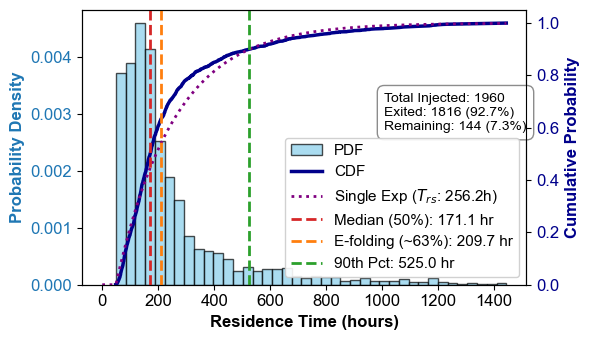

In [6]:
# Exit polygon shapefile
exit_gdf = gpd.read_file('model_boundary/exit_poly_upstream_JWDam.shp') 
exit_poly = exit_gdf.geometry.iloc[0]

# Bounding box of the exit polygon
poly_minx, poly_miny, poly_maxx, poly_maxy = exit_poly.bounds

ny = params.depth.shape[0]
max_y = min_y + (ny * res)

# Initialize a dictionary for residence times (grouped by injection seed)
rtd_by_seed = {f"seed_{i}": [] for i in range(len(seedinds))}
num_seeds = len(seedinds)

# Iterate through all particle drops
for drop_idx, wd in enumerate(tqdm(walk_data_all, desc="Processing Trajectories")):
    seed_id = drop_idx % num_seeds
    
    # Loop over each particle in this specific drop
    for p_i in range(len(wd["xinds"])):
        x_indices = wd["xinds"][p_i]
        y_indices = wd["yinds"][p_i]
        times = wd["travel_times"][p_i]
        
        if len(times) == 0:
            continue
            
        start_time = times[0]
        residence_time = np.nan  
        
        # Go through particle positions
        for step in range(len(x_indices)):
            # convert back to real coordinates (because the polugons are in real coordinates)
            x_real = min_x + (y_indices[step] * res)
            y_real = max_y - (x_indices[step] * res)

            if (poly_minx <= x_real <= poly_maxx) and (poly_miny <= y_real <= poly_maxy):
                # If particle is inside the polygon, compute the residence time
                if exit_poly.contains(Point(x_real, y_real)):
                    residence_time = times[step] - start_time  # Seconds
                    break
                
        rtd_by_seed[f"seed_{seed_id}"].append(residence_time)

# Format outputs:
for seed_key in rtd_by_seed:
    rtd_by_seed[seed_key] = np.array(rtd_by_seed[seed_key])

# Filter out NaNs (particles that never exited) and convert to hours
raw_rtd_seconds = rtd_by_seed["seed_0"]
total_particles = len(raw_rtd_seconds)
valid_rtd_hours = raw_rtd_seconds[~np.isnan(raw_rtd_seconds)] / 3600.0
exited_particles = len(valid_rtd_hours)
exit_pct = (exited_particles / total_particles * 100) if total_particles > 0 else 0.0

# Compute metrics
if exited_particles == 0:
    print(f"\nTotal Injected: {total_particles} | Exited: 0 (0.0%)")
    print("No particles reached the exit polygon.")
else:
    t_50    = np.percentile(valid_rtd_hours, 50)   # Median
    t_efold = np.percentile(valid_rtd_hours, 63.2) # E-folding time
    t_90    = np.percentile(valid_rtd_hours, 90)   # Heavy tail

    # Exponential decay fitting
    sorted_rtd = np.sort(valid_rtd_hours)
    t_lag = sorted_rtd[0]  # The lag (first particle exit time)

    # Define the lagged mathematical models
    def single_exp_lag(t, k):
        return np.where(t < t_lag, 1.0, np.exp(-k * (t - t_lag)))

    exited_counts = np.arange(1, len(sorted_rtd) + 1)
    fraction_remaining = 1.0 - (exited_counts / total_particles)

    # Exponential Fit
    popt_single, _ = curve_fit(single_exp_lag, sorted_rtd, fraction_remaining, p0=[0.1])
    k_single = popt_single[0]
    T_rs = t_lag + (1 / k_single)

    print(f"--- Fitted Coefficients ---")
    print(f"Single Exp  | k: {k_single:.5f}")
    print(f"---------------------------")

    # String for figure name
    tin_m, tend_m = pd.to_datetime(tin).month, pd.to_datetime(tend).month
    flowStage = 'highFlow' if (1 <= tin_m <= 5) and (1 <= tend_m <= 5) else 'lowFlow' 
    
    # ================== Distribution figure ============================
    fig, ax1 = plt.subplots(figsize=(6, 3.5))
    ax2 = ax1.twinx()

    # PDF 
    counts, bins, patches = ax1.hist(valid_rtd_hours, bins=40, density=True, color='skyblue', 
                                     alpha=0.7, edgecolor='black', label='PDF')
    ax1.set_xlabel('Residence Time (hours)', fontweight='bold')
    ax1.set_ylabel('Probability Density', fontweight='bold', color='tab:blue')
    ax1.tick_params(axis='y', labelcolor='tab:blue')

    # CDF 
    sorted_rtd = np.sort(valid_rtd_hours)
    cdf_values = np.arange(1, len(sorted_rtd) + 1) / len(sorted_rtd)
    ax2.plot(sorted_rtd, cdf_values, color='darkblue', linewidth=2.5, label='CDF')

    # Exponential fitted curves
    t_plot = np.linspace(0, max(sorted_rtd), 500)
    fit_single = single_exp_lag(t_plot, k_single)
    ax2.plot(t_plot, 1 - fit_single, color='purple', linestyle=':', linewidth=2, label=f'Single Exp ($T_{{rs}}$: {T_rs:.1f}h)')
    ax2.set_ylabel('Cumulative Probability', fontsize=12, fontweight='bold', color='darkblue')
    ax2.tick_params(axis='y', labelcolor='darkblue')
    ax2.set_ylim([0, 1.05])

    # Vertical Reference Lines
    ax2.axvline(t_50, color='tab:red', linestyle='--', linewidth=2, label=f'Median (50%): {t_50:.1f} hr')
    ax2.axvline(t_efold, color='tab:orange', linestyle='--', linewidth=2, label=f'E-folding (~63%): {t_efold:.1f} hr')
    ax2.axvline(t_90, color='tab:green', linestyle='--', linewidth=2, label=f'90th Pct: {t_90:.1f} hr')

    stats_text = (
        f"Total Injected: {total_particles}\n"
        f"Exited: {exited_particles} ({exit_pct:.1f}%)\n"
        f"Remaining: {total_particles - exited_particles} ({100 - exit_pct:.1f}%)")

    ax1.text(0.68, 0.7, stats_text, transform=ax1.transAxes, fontsize=10, 
             verticalalignment='top', bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.9, edgecolor='grey'))

    lines_1, labels_1 = ax1.get_legend_handles_labels()
    lines_2, labels_2 = ax2.get_legend_handles_labels()
    if lines_1 or lines_2:
        ax2.legend(lines_1 + lines_2, labels_1 + labels_2, loc='lower right', framealpha=0.9)

    plt.tight_layout()
    fig.savefig(os.path.join(output_folder, f"RTD_{total_particles}p_{flowStage}_{hydrograph}_theta{params.theta}.png"), dpi=300, bbox_inches="tight")
    plt.show()

## Save results
To save the particle tracking results with a **pickle** file. Pickle is very convenient here because preserves nested Python dictionaries, NumPy arrays, and raw scalar metrics.

In [7]:
# Put everything together
export_data = {
    "metadata": {
        "flowStage": flowStage,
        "hydrograph": hydrograph,
        "theta": params.theta,
        "total_particles": total_particles,
        "exited_particles": exited_particles,
        "exit_pct": exit_pct,
    },
    "raw_rtd": rtd_by_seed,
    "valid_rtd_hours": valid_rtd_hours,
    "percentiles": {
        "t_50": t_50,
        "t_efold": t_efold,
        "t_90": t_90,
    },
    "exp_fits": {
        "t_lag": t_lag,
        "k_single": k_single,
        "T_rs": T_rs,
        "k1_double": k1_double,
        "k2_double": k2_double,
        "alpha_double": alpha_double,
        "T_rd": T_rd,
    },
    # This is to get all the paths
    # "walk_data_all": walk_data_all 
}

# Export
pkl_path = os.path.join(output_folder, f"RTD_data_{total_particles}p_{flowStage}_{hydrograph}_theta{params.theta}.pkl")
with open(pkl_path, 'wb') as f:
    pickle.dump(export_data, f)

## Generate animation
Create an animation of the particles using the snapshots. The script simply stiches together the frames and creates the animation.

In [7]:
# Get all frames and sort
frame_files = sorted(glob.glob(os.path.join(snapshots_dir, "particles_depth_t*.png")))
valid_frame_files = [f for f in frame_files if os.path.getsize(f) > 0]

# Output video
output_video = os.path.join(output_folder, "particle_tracking.mp4")

# Stitch frames into an MP4
with imageio.get_writer(output_video, fps=5, quality=9) as writer:
    for filename in valid_frame_files:
        try: # make sure there are no corrupted files
            image = imageio.imread(filename)
            if image.shape[2] == 4:
                image = image[:, :, :3]
            writer.append_data(image)
        except Exception as e:
            print(f"Skipping corrupted frame: {filename}")

IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (1219, 1417) to (1232, 1424) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


## Generate particle travel paths
This script is basically the function $\texttt{routines.draw\_travel\_path}$ with some small adjustments to make the plot consistent with the others.

seed_0
Injection point: seed_0
Particles ID: [496, 1326, 1847, 1615, 572, 622, 66, 1059, 1546, 1632, 1448, 9, 319, 1062, 1921, 756, 253, 1484, 139, 1649, 939, 670, 1942, 155, 1023, 110, 744, 1880, 1107, 732, 1444, 922, 1150, 1403, 1911, 1408, 977, 1195, 263, 983, 362, 473, 80, 1394, 523, 957, 154, 1071, 1935, 1136, 897, 149, 691, 1388, 1515, 275, 444, 1469, 1831, 206, 52, 989, 1757, 31, 1407, 128, 450, 949, 1487, 1422, 192, 1668, 986, 232, 1412, 632, 456, 173, 457, 982, 636, 774, 1878, 625, 89, 1429, 718, 1805, 1246, 6, 1742, 1167, 22, 874, 1461, 1458, 15, 1179, 1896, 902, 935, 1566, 221, 1463, 1635, 775, 236, 1359, 1791, 159, 1331, 1450, 178, 462, 164, 1496, 1001, 1867, 1423, 1112, 546, 1011, 815, 1390, 71, 1249, 1667, 1440, 1140, 1138, 1340, 936, 541, 449, 27, 1404, 580, 921, 1724, 1542, 162, 1146, 1925, 1728, 1604, 1239, 1243, 563, 194, 146, 242, 447, 1619, 1780, 402, 1079, 1739, 1938, 644, 1250, 1402, 1953, 969, 1504, 1387, 713, 1035, 1602, 1737, 1944, 1871, 1661, 609, 151, 1048, 1

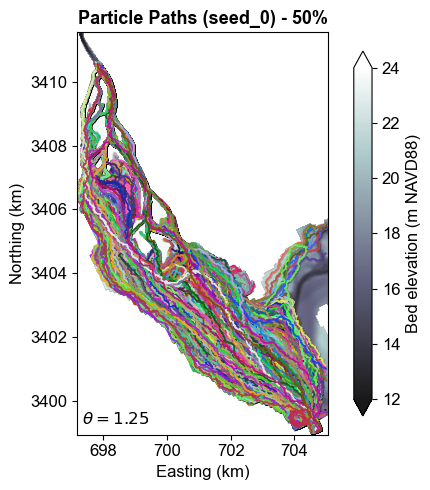

In [11]:
# Plot settings
injection_points_to_plot = ['seed_0'] 
path_percentage          = 50         # Percentage of paths to draw per seed (100 = all)
interval                 = 1          # Number of timestep to consider (1 = all)
plot_legend              = False      # Add legend (Yes/No)

seed_color_map = {'seed_0': 'tab:red'}

# Initialize Figure
fig3, ax3 = plt.subplots(figsize=(6, 5))
im = ax3.imshow(elevation, cmap='bone', alpha=0.9, vmin=12, vmax = 24, extent=grid_extent)
cbar = fig3.colorbar(im, fraction=0.035, extend = 'both')
cbar.ax.set_ylabel('Bed elevation (m NAVD88)')
ax3.set_xlabel('Easting (km)') 
ax3.set_ylabel('Northing (km)')

ny = elevation.shape[0]
max_y = min_y + (ny * res)

seed_to_follow = injection_points_to_plot[0]
print(seed_to_follow)
    
target_walk_data = dorado_data_by_seed[seed_to_follow]
total_particles  = len(target_walk_data['xinds'])

n_sample = max(1, int(total_particles * (path_percentage / 100.0))) if total_particles > 0 else 0
particles_to_follow = random.sample(range(total_particles), n_sample)
ax3.set_title(f'Particle Paths ({seed_to_follow}) - {path_percentage}%', fontweight="bold")
        
print(f"Injection point: {seed_to_follow}\nParticles ID: {particles_to_follow}")

# Vectorize color generation (Random colors)
num_lines = len(particles_to_follow)
colors = np.ones((num_lines, 4))            
colors[:, :3] = np.random.rand(num_lines, 3) 
colors[:, 3] = 0.9                          

# Stack paths
paths = []
for i in particles_to_follow:
    y_idx = np.array(target_walk_data['yinds'][i][0::interval]) 
    x_idx = np.array(target_walk_data['xinds'][i][0::interval])
        
    # Convert indices to kilometers
    easting_km = (min_x + (y_idx * res)) / 1000
    northing_km = (max_y - (x_idx * res)) / 1000
        
    paths.append(np.column_stack((easting_km, northing_km)))

# Add legend if <= 10 paths
if plot_legend and num_lines <= 10:
    custom_lines = [Line2D([0], [0], color=c, lw=1.2) for c in colors]
    ax3.legend(custom_lines, [str(i) for i in particles_to_follow],
                loc='center left', bbox_to_anchor=(1.01, 0.6), title='Particle ID')
elif plot_legend and num_lines > 10:
    print("Legend omitted because more than 10 paths are plotted.")
        
output_name = f"particle_travel_path_{seed_to_follow}.png"

# Add LineCollection to figure
lc = LineCollection(paths, colors=colors, linewidths=1.2, capstyle='round',
                    path_effects=[path_effects.SimpleLineShadow(offset=(0.5, -0.5), alpha=0.2, linewidth=1.6),
                                  path_effects.Normal()])
ax3.add_collection(lc)

# Add text details
ax3.text(0.02, 0.02, fr'$\theta = {params.theta}$', transform=ax3.transAxes, fontsize=12, verticalalignment='bottom')

plt.tight_layout()
plt.savefig(os.path.join(output_folder, output_name), dpi=500, bbox_inches='tight')
plt.show()